## Creating your own lens

GWLENS ships with several built-in axisymmetric lenses (point mass, SIS, CIS, NFW, Plummer sphere, power law, mass sheet), but the solver works for any lensing potential $\psi(x)$ that can be written down analytically. This page shows how to wrap your own potential, check it, and use it like a built-in lens.


### The one rule: `psi` must be analytic

The solver rotates the tail of the diffraction integral into the complex plane, so `psi` is evaluated at **complex** $x$.

<div class="alert alert-warning">

**Rule of thumb**

Use `+ - * / **`, `np.log`, `np.sqrt`, `np.exp`, `np.arccos`, `np.arcsinh`, and similar.
Avoid `np.abs`, `np.hypot`, `np.maximum`, `np.where`, `np.real`, and `if/else` on `x`.

</div>

A lens is a `Potential(psi)`, where `psi(x)` is the lensing potential as a function of the radius $x$. Optional arguments:

- `psi_real`: a faster version for real $x>0$. Use it if `psi` needs complex intermediates on the real axis (as NFW does).
- `q_inf`: $\lim_{x\to\infty}\psi'(x)/x$ (a mass sheet $\kappa$). It is estimated numerically if omitted; passing it skips the estimate.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from gwlens import solver1d as s1d
from gwlens.tools import plotting
plotting.apply_figure_style()

### From scratch: a cored and tidally truncated isothermal halo

Real halos are not infinite. A subhalo orbiting inside a larger host is stripped at its edge, so its mass stays finite. We want a lens that

- has a **core** of radius $a$ (no central singularity),
- behaves like an **isothermal sphere** for $a \ll x \ll s$,
- is **truncated** at radius $s$, so the total mass is finite.

Instead of guessing $\psi(x)$, we start from the surface density. In the units used here the lens potential obeys $\psi'(x) = m(x)/x$, where $m(x) = 2\int_0^x \kappa(x')\,x'\,dx'$ is the projected mass inside $x$. As a check, a point mass has $m =$ constant, an SIS has $m \propto x$, and a mass sheet has $m = \kappa x^2$, which reproduce the built-in potentials. A cored and truncated isothermal profile is

$$
\kappa(x) = \frac{\psi_0}{2}\left[\frac{1}{\sqrt{x^2+a^2}} - \frac{1}{\sqrt{x^2+s^2}}\right], \qquad a < s.
$$

Integrating once gives the enclosed mass

$$
m(x) = \psi_0\left[\left(\sqrt{x^2+a^2}-a\right) - \left(\sqrt{x^2+s^2}-s\right)\right],
$$

and integrating $m(x)/x$ gives the potential

$$
\psi(x) = \psi_0\left[\left(r_a - a\right) - \left(r_s - s\right) - a\ln\frac{a + r_a}{2a} + s\ln\frac{s + r_s}{2s}\right],
\qquad r_a = \sqrt{x^2+a^2},\; r_s = \sqrt{x^2+s^2}.
$$

Its limits are:

- for $a \ll x \ll s$: $\psi \approx \psi_0\, x$, the SIS;
- for $x \gg s$: $\psi \to \psi_0 (s-a)\ln x$, a **point mass** with $m = \psi_0(s-a)$;
- $\psi'(x)/x \to 0$ at large $x$, so there is no mass sheet and we can pass `q_inf=0`.

The potential only uses square roots and logarithms, so it is analytic on the rotated contour.

Before solving anything, we check that the potential has the mass profile we intended. The quantity $x\,\psi'(x)$ is the projected mass enclosed within radius $x$, so it should rise through the core, follow the SIS line $\psi_0 x$ in between, and flatten at the total mass $\psi_0(s-a)$ beyond the truncation.

check_analytic: derivative mismatch 4.0e-09, Im psi 0.0e+00, psi_real 6.6e-16


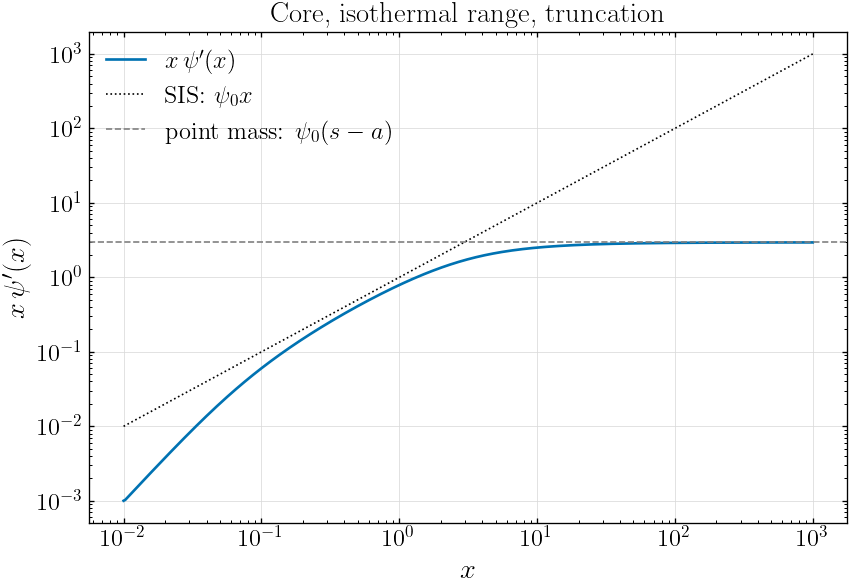

In [18]:
def psi_halo(x, psi0=1.0, a=0.05, s=3.0):
    """Potential of a cored (core radius = a), tidally truncated (truncation radius = s) isothermal halo."""
    ra, rs = np.sqrt(x * x + a * a), np.sqrt(x * x + s * s)
    return psi0 * ((ra - a) - (rs - s) - a * np.log((a + ra) / (2 * a))
                   + s * np.log((s + rs) / (2 * s)))

def truncated_halo(psi0=1.0, a=0.05, s=3.0):
    """The same potential as a lens, which the solver can use."""
    if not 0 < a < s:
        raise ValueError("need 0 < a < s")
    return s1d.Potential(lambda x: psi_halo(x, psi0, a, s), q_inf=0.0)

truncated_halo(1.0, 0.05, 3.0).check_analytic(verbose=True)

x = np.geomspace(1e-2, 1e3, 400)
slope = np.gradient(psi_halo(x), np.log(x))      # d psi / d ln x = x psi'

fig, ax = plt.subplots()
ax.loglog(x, slope, label=r"$x\,\psi'(x)$")
ax.loglog(x, x, "k:", lw=1, label="SIS: $\\psi_0 x$")
ax.axhline(3.0 - 0.05, color="gray", ls="--", lw=1, label="point mass: $\\psi_0(s-a)$")
ax.set(xlabel="$x$", ylabel=r"$x\,\psi'(x)$", title="Core, isothermal range, truncation")
ax.legend(); plt.show()

The curve falls below the SIS line at small $x$ (the core removes the central mass) and levels off at $\psi_0(s-a)$ for $x \gg s$ (the truncation). The stretch between them follows the SIS only roughly, since $s=3$ is not much larger than $a=0.05$ in this example. Making $s$ larger widens it.

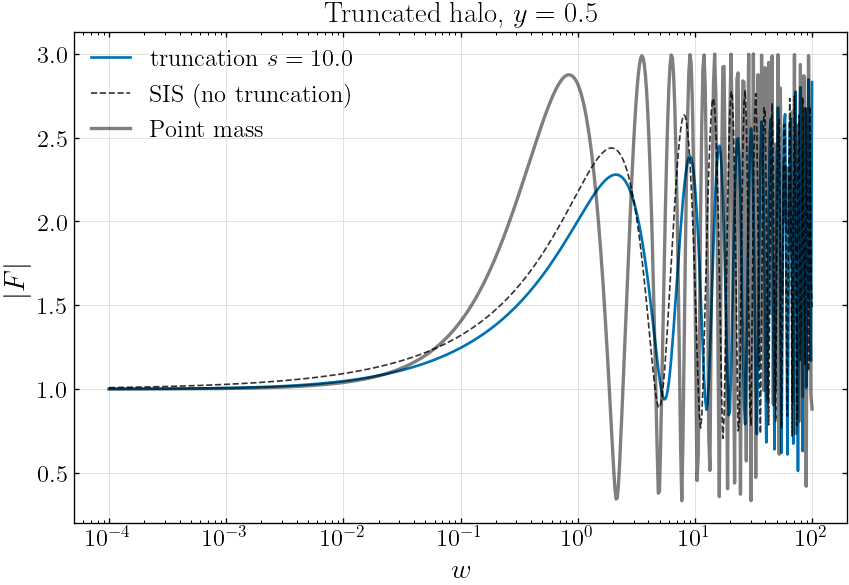

In [19]:
y = 0.5
ws = np.geomspace(0.0001, 100, 600)
s= 10.0 #truncation radius of our halo
fig, ax = plt.subplots()
F0 = s1d.amplification_many(ws, y, truncated_halo(1.0, 0.05, s))
ax.semilogx(ws, np.abs(F0), label=f"truncation $s={s}$")
F1 = s1d.amplification_many(ws, y, s1d.sis(1.0))
F2 = s1d.amplification_many(ws, y, s1d.point_mass(5.0))
ax.semilogx(ws, np.abs(F1), "k--", lw=1, alpha=0.8, label="SIS (no truncation)")
ax.semilogx(ws, np.abs(F2), "k-", lw=2, alpha=0.5, label="Point mass")
ax.set(xlabel="$w$", ylabel="$|F|$", title=f"Truncated halo, $y={y}$")
ax.legend(); plt.show()

Now let us do some more comparisons against point mass and SIS lenses to see what our lens behaves like. 

In [20]:
from matplotlib.lines import Line2D

y, psi0, a = 0.3, 1.0, 0.05
ws = np.geomspace(1e-4, 100, 500)
s_values = (0.5, 4.0, 10.0)
colors = plt.cm.viridis(np.linspace(0.1, 0.85, len(s_values)))

def amp(lens):
    return np.abs(s1d.amplification_many(ws, y, lens))

# truncated halo for each truncation radius s
halo = {s: amp(truncated_halo(psi0, a, s)) for s in s_values}

def compare(ref, ref_label, ref_color, wzoom, title):
    """Solid: truncated halo. Dotted: reference lens (same colour as the halo, or ref_color)."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True,
                             gridspec_kw={"width_ratios": [1.3, 1]})
    for ax, wmax in zip(axes, (100, wzoom)):
        m = ws <= wmax
        for s, c in zip(s_values, colors):
            ax.semilogx(ws[m], halo[s][m], color=c, lw=1.8)
            ax.semilogx(ws[m], ref[s][m], color=ref_color or c, lw=1.2, ls=":")
        ax.set_xlabel("$w$")

    handles = [Line2D([], [], color=c, lw=1.8, label=f"$s={s}$")
               for s, c in zip(s_values, colors)]
    handles += [Line2D([], [], color="gray", lw=1.8, label="truncated halo"),
                Line2D([], [], color=ref_color or "gray", lw=1.2, ls=":", label=ref_label)]
    axes[0].set(ylabel="$|F|$", title="Full range")
    axes[0].legend(handles=handles, loc="upper left", fontsize=8)
    axes[1].set(title="At lower frequencies")
    axes[1].legend(handles=handles, loc="upper left", fontsize=8)
    fig.suptitle(title, y=1.05, fontsize=18)
    plt.show()


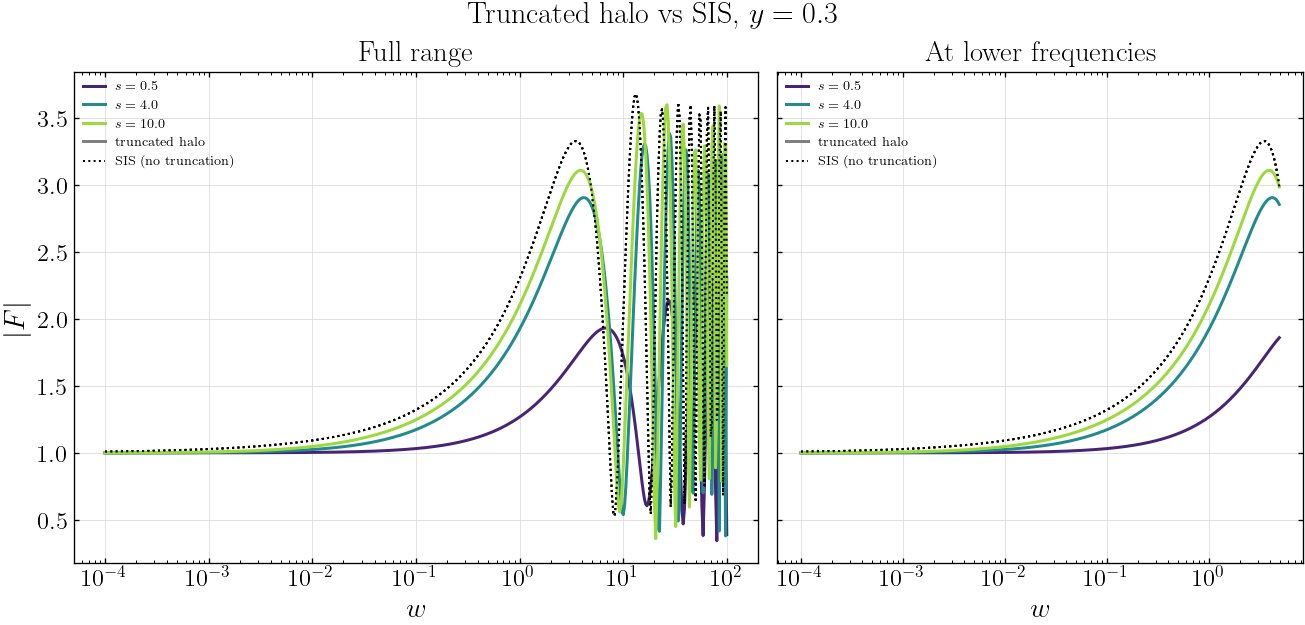

In [21]:
# 1) against an untruncated SIS
F_sis = amp(s1d.sis(psi0))
compare({s: F_sis for s in s_values}, "SIS (no truncation)", "k", 5,
        f"Truncated halo vs SIS, $y={y}$")

At high frequency (short wavelength) all the curves show an SIS-like behaviour, because the wave only probes the isothermal part of the halo. Let's now compare the behaviour against point masses of similar total mass.

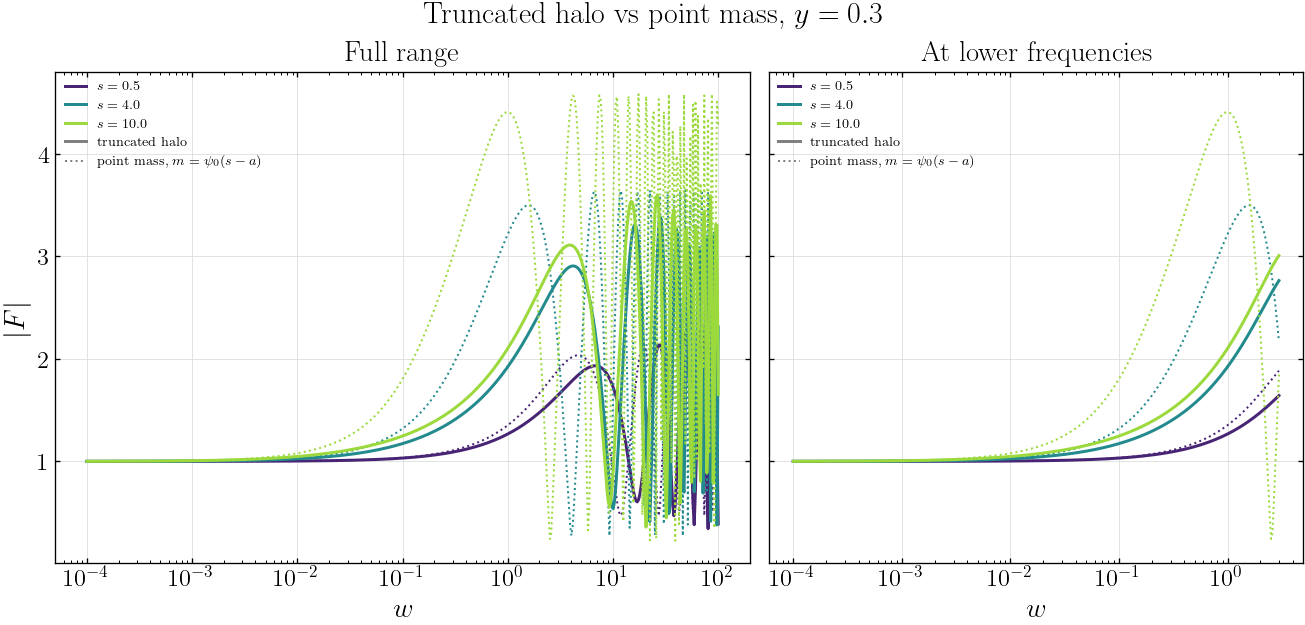

In [22]:
# 2) against a point mass of the same total mass
pml = {s: amp(s1d.point_mass(psi0 * (s - a))) for s in s_values}
compare(pml, r"point mass, $m=\psi_0(s-a)$", None, 3,
        f"Truncated halo vs point mass, $y={y}$")

At low frequency the wave is much longer than the halo, so the lens is unresolved and only its total mass $\psi_0(s-a)$ matters. The amplification approaches that of a point mass of the same mass as the halo. The curves separate once the wave starts to resolve the halo. The larger the truncation radius, the lower the frequency at which this happens.

### What happens if `psi` is not analytic?

`Solver1D` calls `check_analytic()` automatically when it is built. For example, a potential that uses `np.abs` looks fine on the real axis but is invalid on the rotated tail, and the check warns about it:

In [23]:
psi_test = s1d.Potential(lambda x: np.abs(x))        # NOT analytic
mismatch = psi_test.check_analytic(verbose=True)
#print("The derivative mismatch is:", mismatch)

check_analytic: derivative mismatch 5.0e-01, Im psi 0.0e+00, psi_real 0.0e+00


/home/ansalk/GWLENS/gwlens/solver/solver1d.py:155: UserWarning: psi does not look analytic (derivative mismatch 5.0e-01, Im psi on the real axis 0.0e+00, psi_real vs psi 0.0e+00). Use only analytic numpy operations (no abs/hypot/where/real/if-else on x); otherwise the rotated tail is invalid.
  warnings.warn(


Note that the truncated halo we used above didn't throw this warning when we implemented it. 